# LeWM: a robot world model trained end-to-end from pixels

[LeWorldModel](https://arxiv.org/abs/2603.19312) ([code](https://github.com/lucas-maes/le-wm)) learns its encoder and predictor jointly from raw pixels, with no frozen backbone and no EMA target. Its loss has two terms: next-embedding prediction, and SIGReg, which keeps the embeddings Gaussian so they cannot collapse.

The robot is a **Universal Robots UR10e** with a Robotiq 2F-85 gripper, simulated in [MuJoCo](https://mujoco.org) on single-cube pick-and-place after [OGBench](https://github.com/seohongpark/ogbench) `cube-single`, one of the paper's benchmarks. Needs `pip install torch-world[robotics]`.

In [1]:
import itertools

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import RobotCube
from torch_world.models import LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import recompute_batchnorm

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
ROBOT = dict(robot="ur10e", size=96, control_dt=0.2, max_step=0.1)

## Play data
A noisy scripted policy picks the cube up and puts it down at random spots, like OGBench's `play` datasets. Actions move the gripper by up to 10 cm and open or close it, five times a second. Episodes are cut into windows of `history + 1` frames.

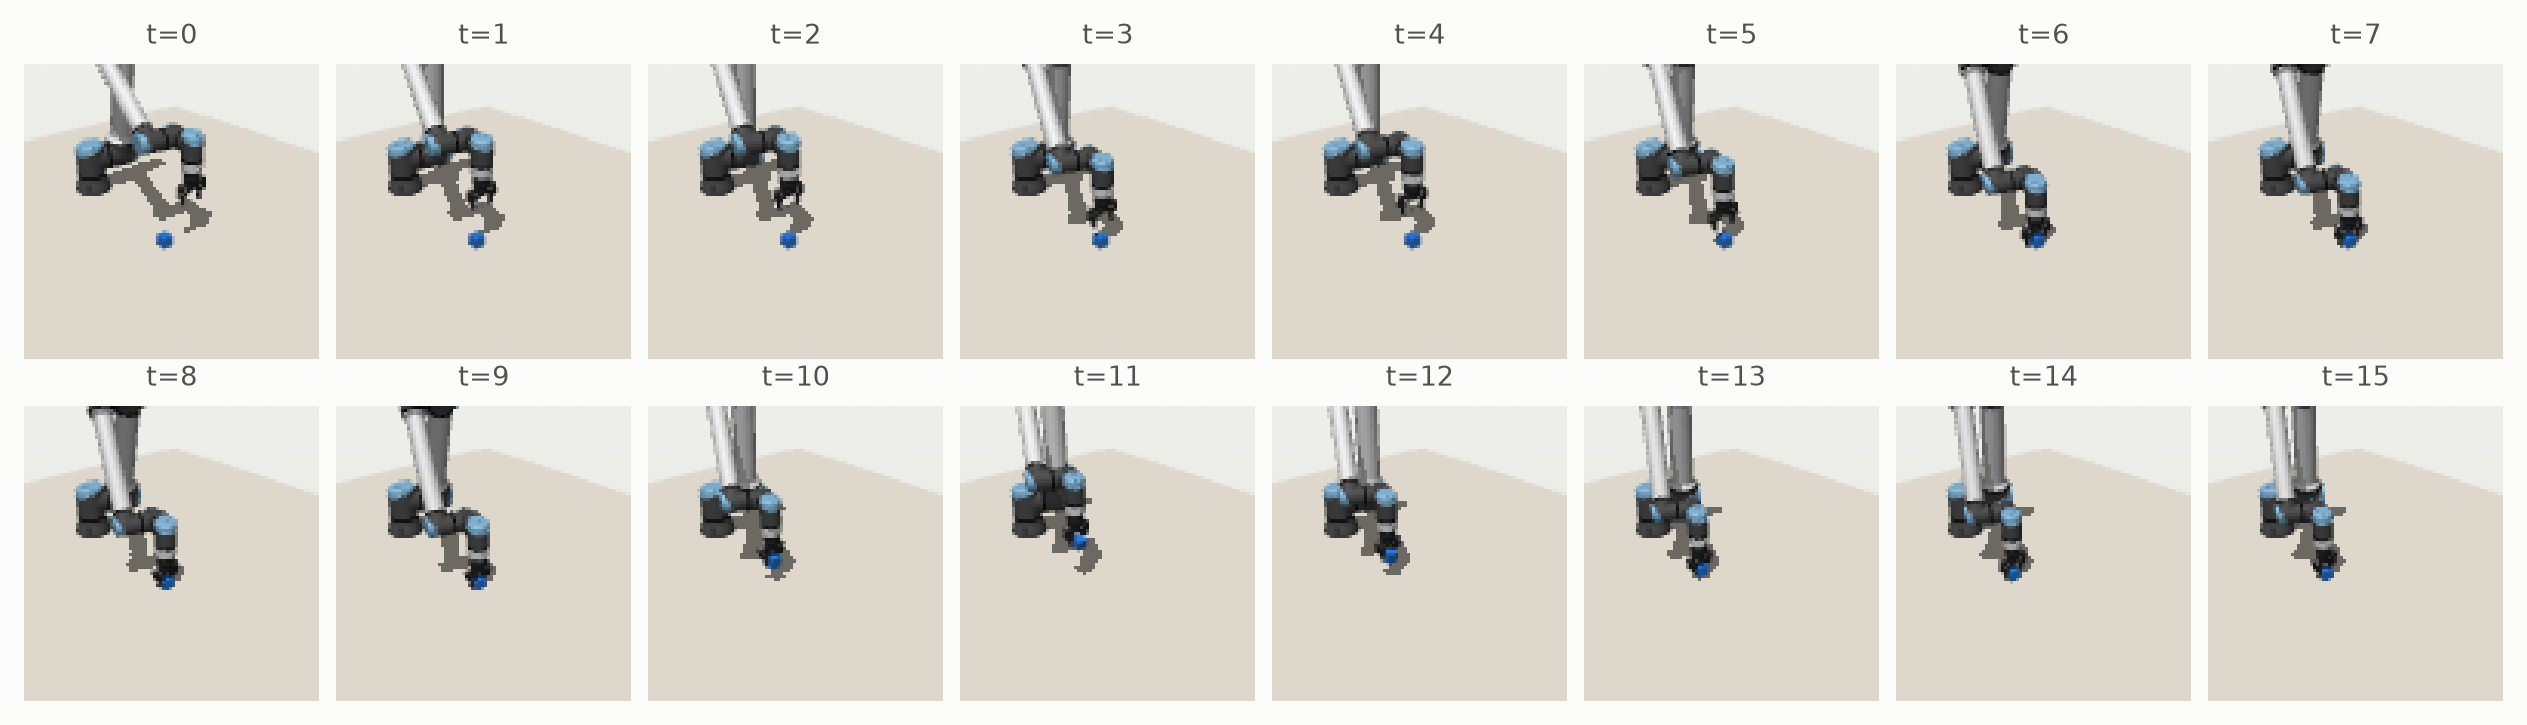

In [2]:
HISTORY = 3
env = RobotCube(batch_size=1024, **ROBOT)
data = {k: v.to(device) for k, v in env.collect(24, generator=torch.Generator().manual_seed(0)).items()}
loader = DataLoader(TrajectoryDataset(data, HISTORY + 1), batch_size=256, shuffle=True, drop_last=True)
plots.images(data["pixels"][2, :16].cpu(), [f"t={t}" for t in range(16)], size=1.3)

## Model
A small ViT whose CLS token embeds each frame, trained from scratch together with the predictor. The SIGReg weight is λ = 0.05.

In [3]:
encoder = CLSEncoder(img_size=96, patch_size=12, embed_dim=192, depth=6, num_heads=6)
model = LeWM(encoder, action_dim=4, embed_dim=192, history=HISTORY, depth=6, num_heads=8, head_dim=32, mlp_dim=768, proj_dim=768, lamb=0.05).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

7.79M parameters


## Train

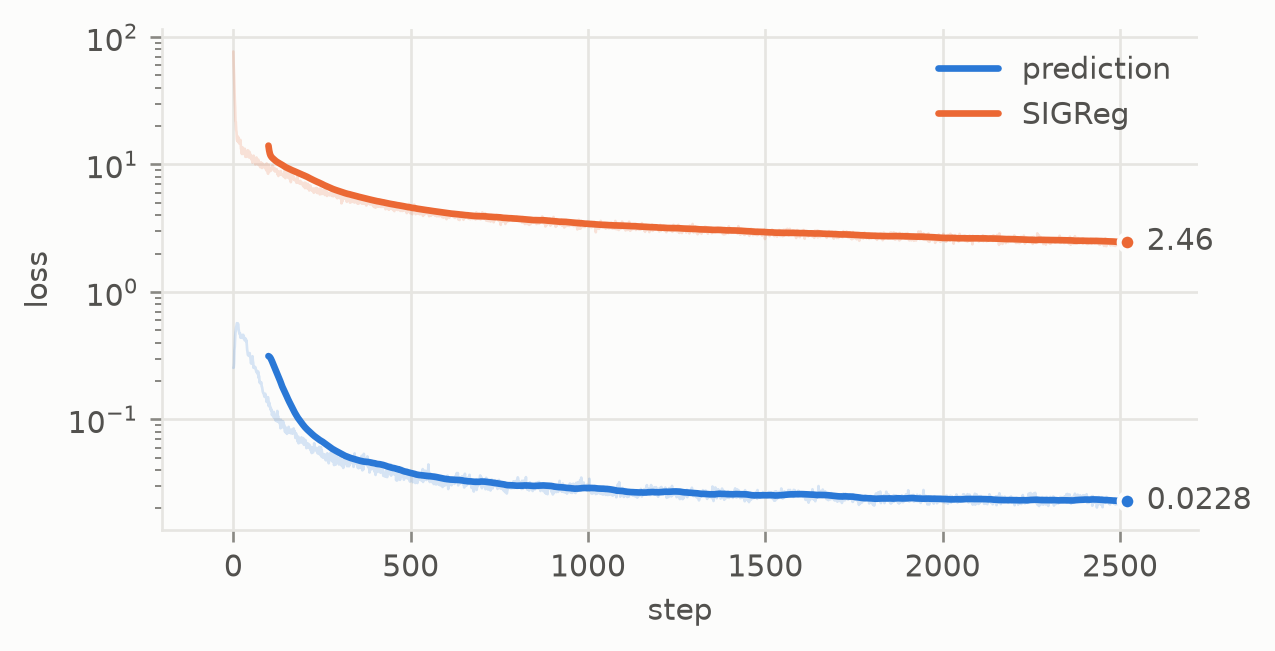

In [4]:
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-3)
log = {"prediction": [], "SIGReg": []}
for epoch in range(30):
    for batch in loader:
        out = model(batch["pixels"], batch["actions"])
        opt.zero_grad()
        out["loss"].backward()
        opt.step()
        log["prediction"].append(out["pred_loss"].item())
        log["SIGReg"].append(out["sigreg_loss"].item())

recompute_batchnorm(model, itertools.islice(loader, 50), lambda b: model(b["pixels"], b["actions"]))
model.eval()
plots.curves(log, smooth=100)

## What the embedding knows
Linear probes from frozen LeWM embeddings to the gripper and cube positions, fit on 4096 play frames and evaluated on 1024 others.

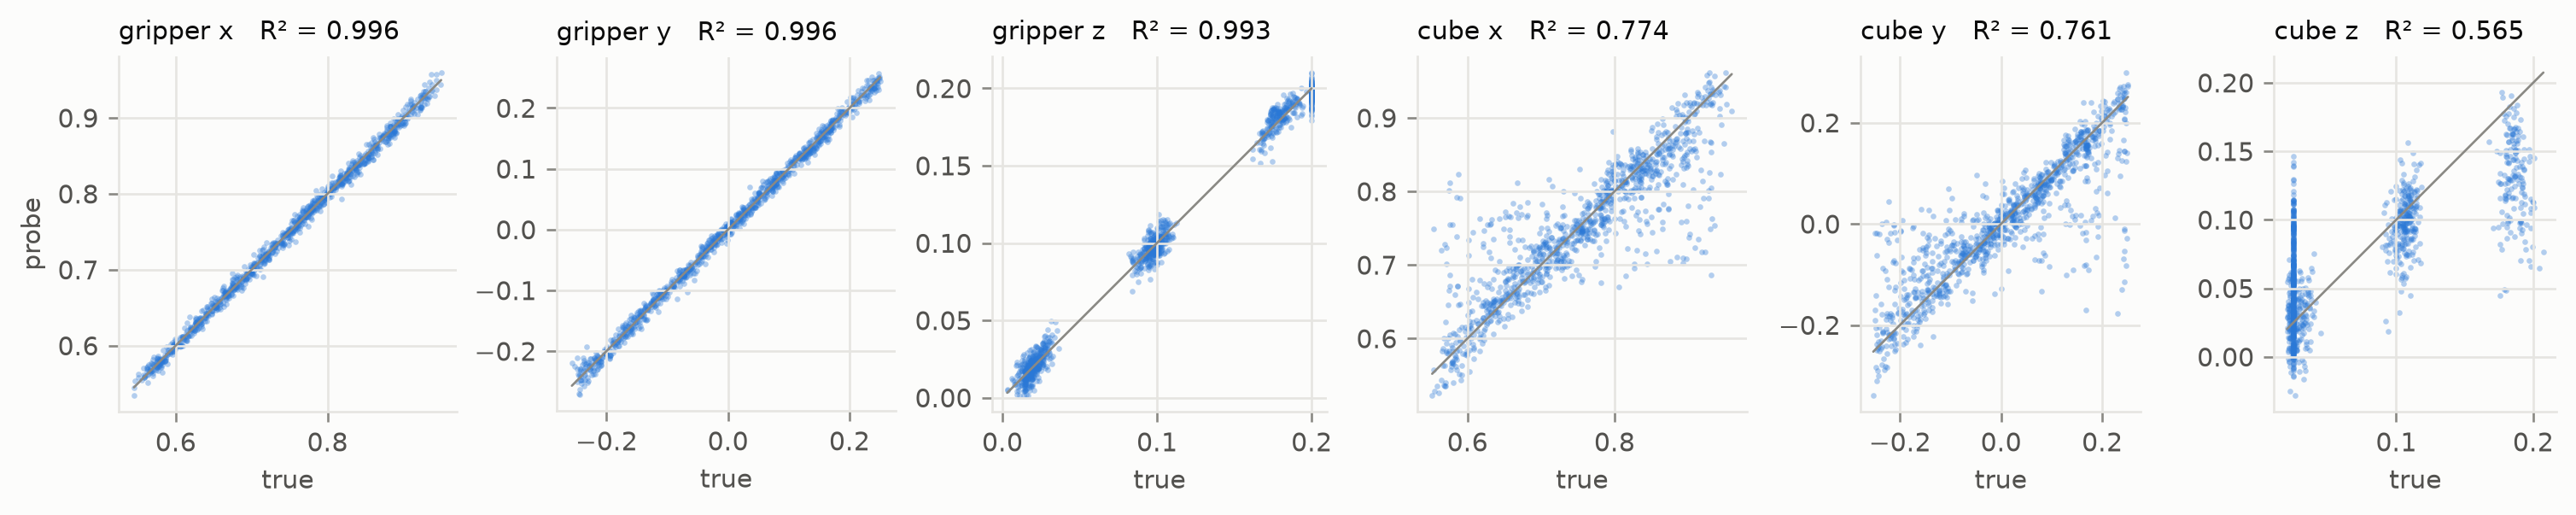

In [5]:
frames, states = data["pixels"][:, ::4].flatten(0, 1)[:5120], data["states"][:, ::4].flatten(0, 1)[:5120]
with torch.no_grad():
    z = torch.cat([model.encode(f[:, None])[:, 0] for f in frames.split(1024)])
x = torch.cat([z, torch.ones(len(z), 1, device=device)], 1)
targets = {"gripper x": 0, "gripper y": 1, "gripper z": 2, "cube x": 4, "cube y": 5, "cube z": 6}
y = states[:, list(targets.values())]
w = torch.linalg.lstsq(x[:4096], y[:4096]).solution
plots.probes(y[4096:], x[4096:] @ w, list(targets), size=2.1)

## Plan toward goal images
Each task moves the cube elsewhere on the table; the goal is the image of the finished task, arm included. CEM searches 5-step action sequences whose imagined final embedding is closest to the goal's, and MPC executes the first action. Success means the cube rests within one cube width (5 cm) of its goal.

LeWM + CEM               success 0.00
scripted expert          success 1.00
random actions           success 0.00
LeWM + CEM picked the cube up in 0% of episodes


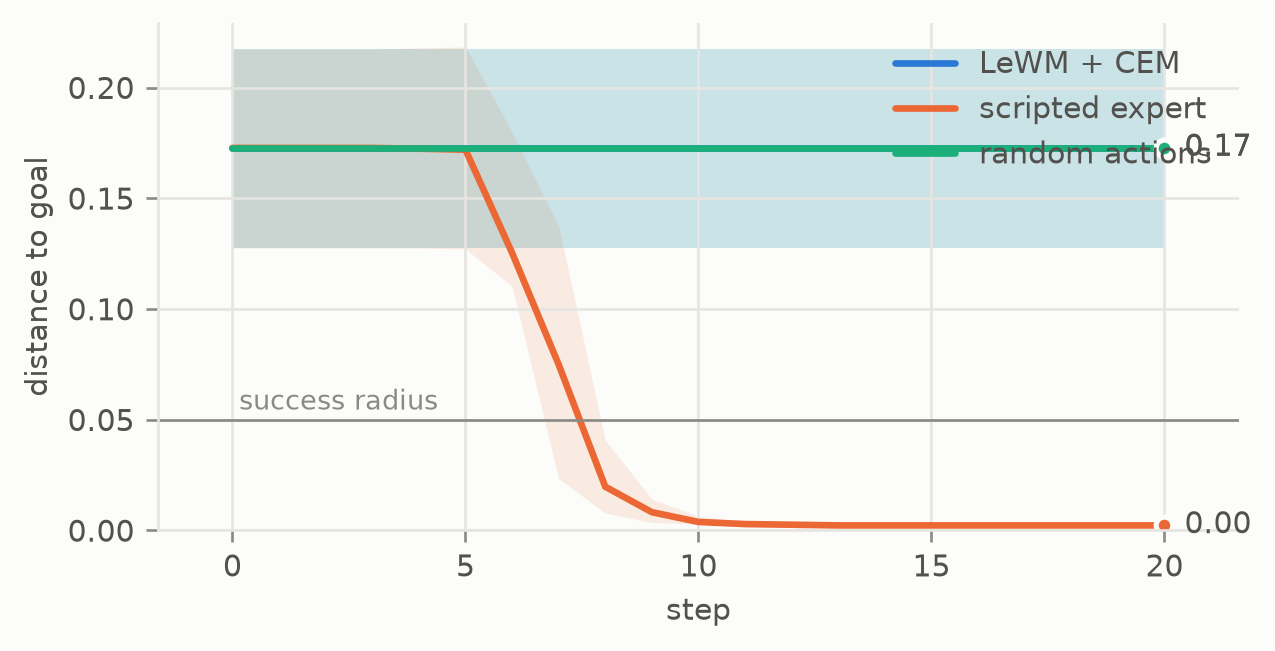

In [6]:
env = RobotCube(batch_size=16, **ROBOT)
env.reset(generator=torch.Generator().manual_seed(1))
start = env.state.clone()
goal_state = env.solve(env.sample_targets(generator=torch.Generator().manual_seed(2)), 24)
with torch.no_grad():
    goal = model.encode(env.render(goal_state)[:, None].to(device))[:, 0]

planner = CEM(horizon=5, action_dim=4, num_samples=256, num_elites=32, iterations=10, bounds=(-1, 1))
plan = lambda obs: planner(model, model.encode(obs[:, None].to(device)), goal)[:, 0].cpu()
policies = {"LeWM + CEM": plan, "scripted expert": lambda obs: env.expert(goal_state[:, 4:6]), "random actions": evaluation.random_policy(env)}
results = evaluation.goal_reaching(env, policies, start, goal_state, steps=20)
paths = results.paths["LeWM + CEM"]
print(results)
print(f"LeWM + CEM picked the cube up in {(paths[..., 6] > env.half + 0.01).any(1).float().mean():.0%} of episodes")
plots.distances(results.distances, radius=env.radius)

The first episode, frame by frame, next to its goal image:

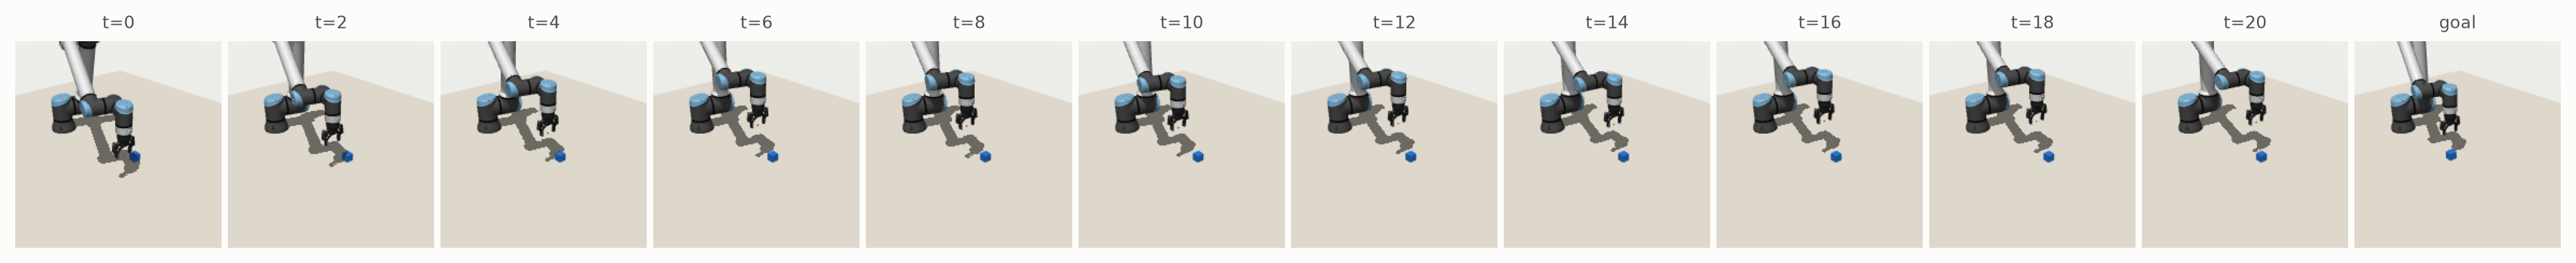

In [7]:
keep = list(range(0, 20 + 1, 2))
plots.images(torch.cat([env.render(paths[0, keep], size=192), env.render(goal_state[:1], size=192)]), [f"t={t}" for t in keep] + ["goal"], ncols=len(keep) + 1, size=1.4)

Where the cube went (the path darkens over time), seen from above:

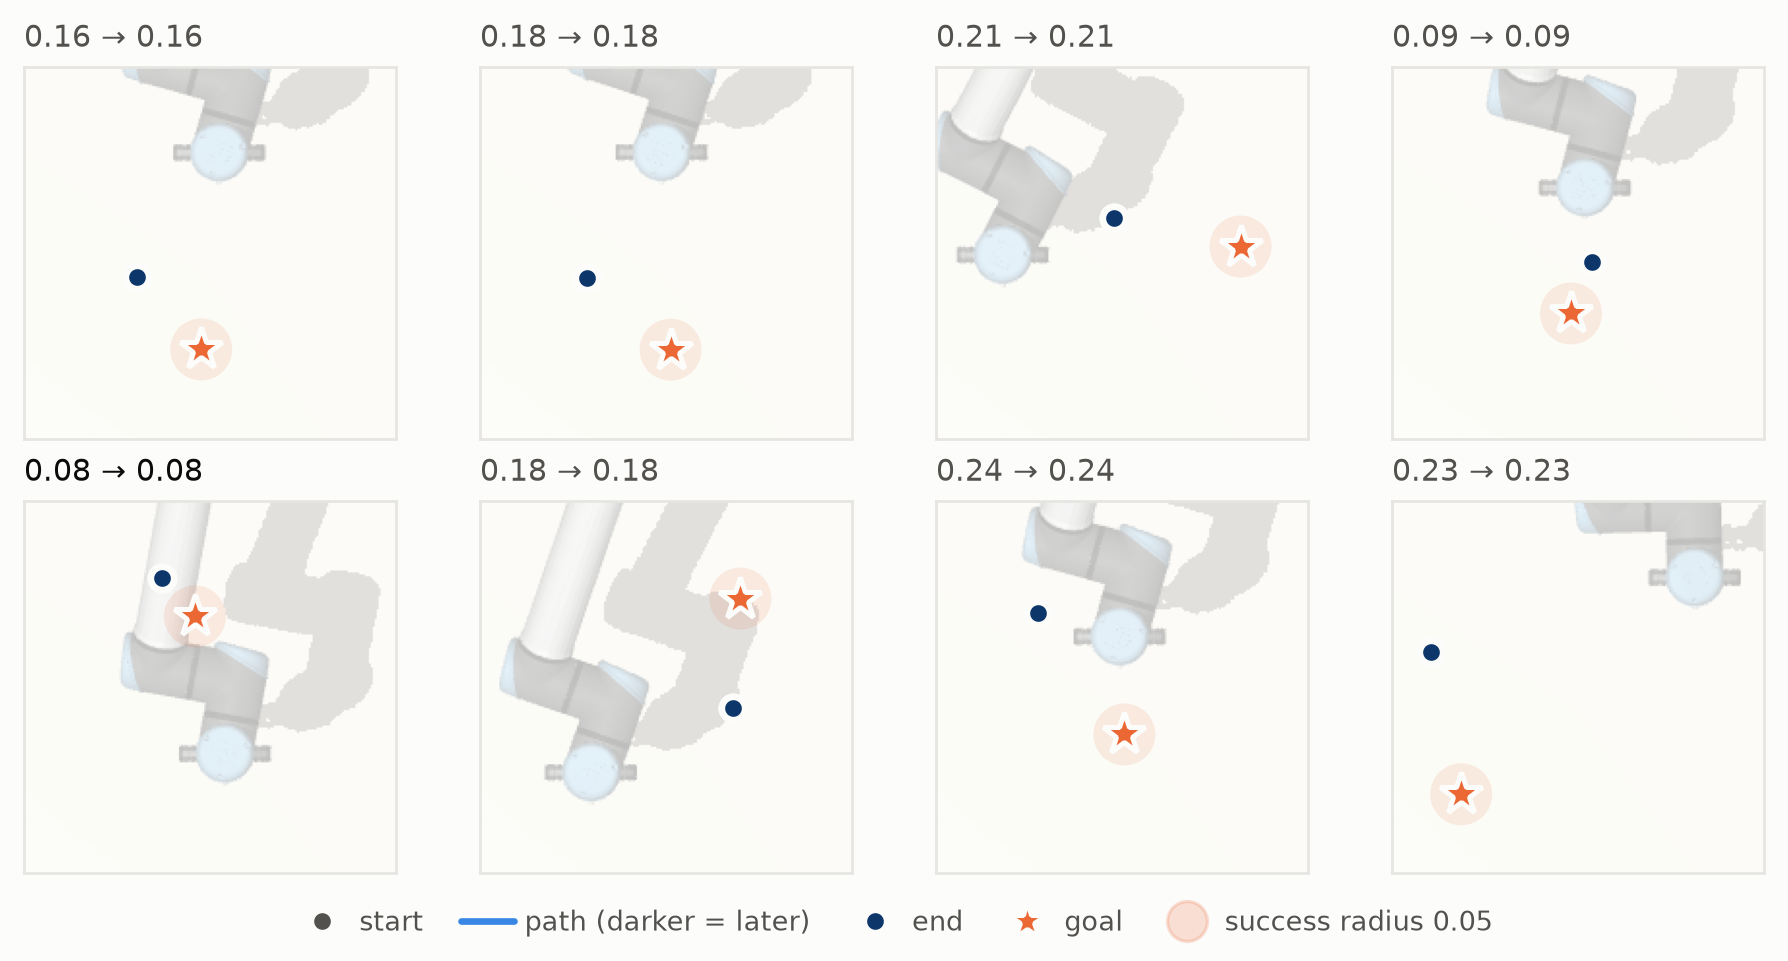

In [8]:
plots.trajectories(env.position(paths[:8]), env.position(goal_state[:8]), radius=env.radius / env.top_size, scale=env.top_size, background=env.render(goal_state[:8], camera="top", size=192))